# FXS / 01 — USDCAD: stacked 1-minute days, discovery 2016–2020

Protocols: [`001`](../../../discussions/FX_Intraday_Seasonality/001_claude_fxs01_preregistration.md) (design), [`002`](../../../discussions/FX_Intraday_Seasonality/002_claude_fxs01_amendment_per_pair.md) (one study per pair).

Every trading day of USDCAD is laid on top of the others by minute of day, in two clocks (`NY`: 17:00→17:00 New York; `UTC`: 00:00→24:00). Every interval (start every 5 minutes, 15–240 minutes long: 2,704 tests) is tested for a non-zero mean.

| Filter | Condition |
|---|---|
| D1 | Benjamini–Hochberg over this pair's 2,704 tests, q ≤ 0.05 |
| D2 | same sign in ≥ 4 of 5 years |
| D3 | \|mean\| > median spread (start, end) + 0.70 bp commission |
| D0 | real D1–D3 count above the 95th percentile of 20 rotated-day placebos |
| reported | passes Bonferroni over the pooled 40,560 tests (\|t\| ≥ 4.84) |

**Reads 2016–2020 only** (enforced in code) and only once the download is complete. Writes `USDCAD/01/candidates_frozen.csv`: commit it before running `USDCAD/02_confirmation.ipynb`.

In [1]:
PAIR = "USDCAD"

import json, os, sys, tempfile
import datetime as dt
from dataclasses import replace, asdict
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

SYNTHETIC = os.environ.get("FXS_SYNTHETIC") == "1"
if SYNTHETIC:                                   # never touch the real market-data folder in a smoke run
    os.environ["EQUITY_TRADING_DIR"] = os.environ.get("FXS_SYNTH_DIR") or tempfile.mkdtemp(prefix="fxs_")
    os.environ["FXS_SYNTH_DIR"] = os.environ["EQUITY_TRADING_DIR"]
    os.environ.pop("DUKASCOPY_DIR", None)

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "equity_trading").exists())
sys.path.insert(0, str(ROOT / "src"))
from equity_trading import fx_seasonality as F

cfg = F.FXSConfig()
if SYNTHETIC:
    cfg = replace(cfg, n_placebo=3, n_boot=2_000)
POOLED_T = F.bonferroni_t(F.pooled_n_tests(cfg))
HOURS = lambda clock, step: ([60 * h for h in range(0, 25, step)], [F.slot_label(clock, 60 * h).split()[1] for h in range(0, 25, step)])
pd.set_option("display.width", 220, "display.max_columns", 40, "display.max_rows", 120)
OUT = Path.cwd() / ("01_synthetic" if SYNTHETIC else "01"); OUT.mkdir(exist_ok=True)
START, END = F.DISCOVERY
print(f"{PAIR} | fx_seasonality {F.FXS_VERSION} | synthetic={SYNTHETIC} | {START} -> {END} | pooled Bonferroni |t| {POOLED_T:.2f}")

USDCAD | fx_seasonality 0.2.0 | synthetic=False | 2016-01-01 -> 2020-12-31 | pooled Bonferroni |t| 4.85


## 0. Synthetic inputs (smoke run only)

In [2]:
if SYNTHETIC:
    base = Path(os.environ["EQUITY_TRADING_DIR"]) / "Dukascopy"
    if not F.candles_root(PAIR).exists():
        for a, b in [(dt.date(2015, 12, 28), dt.date(2020, 12, 31)), (dt.date(2020, 12, 28), dt.date(2025, 12, 31))]:
            F.write_synthetic_candles(base, PAIR, a, b, seed=a.year, drift_bps=4.0 if PAIR == "EURUSD" else 0.0,
                                      price=110.0 if PAIR.endswith("JPY") else 1.10)

## 1. Download complete?

At least 99% of the expected UTC day files (Saturdays excluded) must exist. If the download is still running this cell stops; rerun the notebook when it has finished.

In [3]:
cov = F.file_coverage(PAIR, START, END)
print(f"{PAIR}: {cov['present']}/{cov['expected']} day files ({cov['share']:.2%}); missing {len(cov['missing'])}, "
      f"of which logged as gaps {len(cov['missing_logged_as_gap'])}")
if cov["missing"]:
    print("missing days (first 30):", [str(d) for d in cov["missing"][:30]])
assert cov["share"] >= cfg.min_file_share, "download not complete for the discovery window: wait and rerun"

USDCAD: 1567/1567 day files (100.00%); missing 0, of which logged as gaps 0


## 2. Candle close check against the USD/JPY ticks

The downloader checks every file's layout. This compares the minute **close** with the last tick of each minute on the Tokyo-morning USD/JPY ticks (March 2016). It runs once USD/JPY candles exist; ≈ 100% matches expected.

In [4]:
tick_root = F.candles_root("USDJPY").parent / "hours_00-01-02-22-23"
if not SYNTHETIC and tick_root.exists() and F.candles_root("USDJPY").exists():
    val = F.validate_against_ticks("USDJPY", F.candles_root("USDJPY"), tick_root,
                                   [dt.date(2016, 3, d) for d in range(1, 32) if dt.date(2016, 3, d).weekday() < 5])
    if len(val):
        display(val[["minutes", "bid_close_match", "ask_close_match"]].describe().loc[["count", "mean", "min"]])
        assert val["bid_close_match"].mean() > 0.95, "candle close does not match ticks: stop and report"
    else:
        print("USD/JPY March 2016 candles not downloaded yet: check pending")
else:
    print("check pending (USD/JPY candles or ticks not available)")

,minutes,bid_close_match,ask_close_match
count,23.000000,23.0,23.0
mean,278.913043,1.0,1.0
min,180.000000,1.0,1.0


## 3. Stack the days

In [5]:
panels = F.load_panels([PAIR], START, END, "discovery", cfg)
display(pd.DataFrame([{"clock": c, "days": len(v.dates), "first": str(v.dates[0]), "last": str(v.dates[-1]),
                       "median_coverage": float(np.median(v.coverage)), "median_spread_bps": float(np.median(v.spread_bps())),
                       "price_first": float(v.mid[0, 0]), "price_last": float(v.mid[-1, -1])}
                      for (p, c), v in panels.items()]).round(4))

,clock,days,first,last,median_coverage,median_spread_bps,price_first,price_last
0,NY,1297,2016-01-04,2020-12-31,1.0000,0.8003,1.3838,1.2727
1,UTC,1297,2016-01-04,2020-12-31,0.9993,0.8014,1.3875,1.2727


## 4. The stacked day

Top: mean cumulative mid return from the day start (bps) ± 2 standard errors. Bottom: the same path for each year separately. Structure that is real shows up in most years at the same time of day.

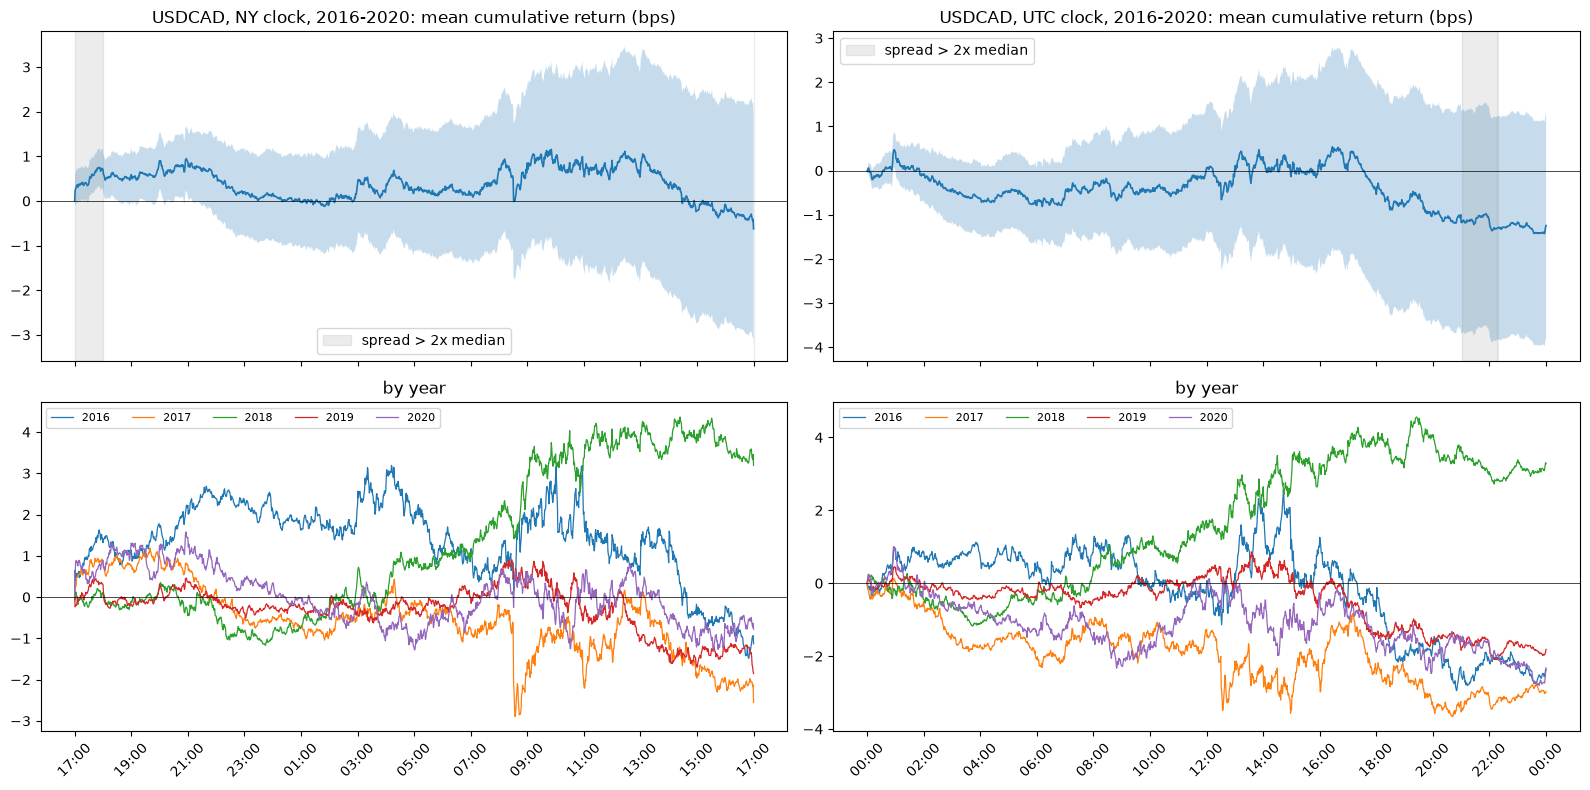

In [6]:
prof = {c: F.profile(panels[(PAIR, c)]) for c in F.CLOCKS}
fig, axes = plt.subplots(2, 2, figsize=(16, 8), sharex="col")
for j, clock in enumerate(F.CLOCKS):
    pr, x = prof[clock], prof[clock].index / 60
    ax = axes[0, j]
    ax.plot(x, pr["cum_mean_bps"], lw=1.2)
    ax.fill_between(x, pr["cum_mean_bps"] - 2 * pr["cum_se_bps"], pr["cum_mean_bps"] + 2 * pr["cum_se_bps"], alpha=0.25)
    wide = (pr["spread_bps"] > 2 * pr["spread_bps"].median()).to_numpy()
    ax.fill_between(x, 0, 1, where=wide, transform=ax.get_xaxis_transform(), color="grey", alpha=0.15, label="spread > 2x median")
    ax.axhline(0, color="black", lw=0.5); ax.set_title(f"{PAIR}, {clock} clock, 2016-2020: mean cumulative return (bps)"); ax.legend()
    yp = F.yearly_profiles(panels[(PAIR, clock)])
    for y in yp.columns:
        axes[1, j].plot(x, yp[y], lw=0.9, label=str(y))
    axes[1, j].axhline(0, color="black", lw=0.5); axes[1, j].legend(ncol=5, fontsize=8); axes[1, j].set_title("by year")
    t, l = HOURS(clock, 2)
    axes[1, j].set_xticks(np.array(t) / 60); axes[1, j].set_xticklabels(l, rotation=45)
plt.tight_layout(); plt.savefig(OUT / "01_stacked_day.png", dpi=110); plt.show()
pd.DataFrame({c: prof[c]["cum_mean_bps"] for c in F.CLOCKS}).to_csv(OUT / "01_profile_cum_mean.csv")

## 5. Activity and cost by minute of day

Mean absolute 1-minute return and median spread. Structure here is certain (sessions, rollover) and is not a direction signal; it shows where trading is cheap.

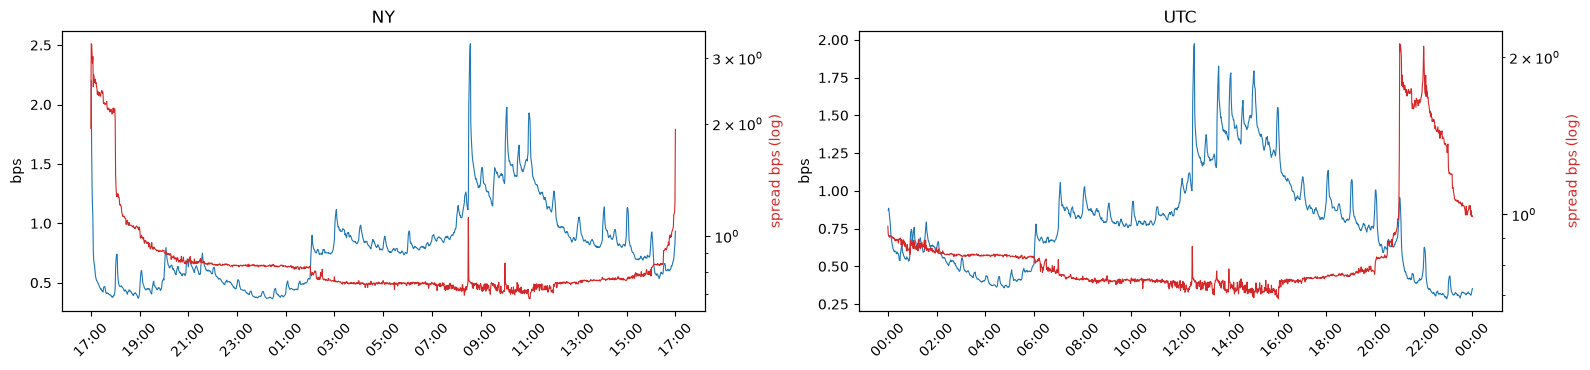

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 3.8))
for j, clock in enumerate(F.CLOCKS):
    pr = prof[clock]
    ax = axes[j]; ax2 = ax.twinx()
    ax.plot(pr.index / 60, pr["abs_ret_bps"].rolling(5, min_periods=1).mean(), lw=0.8, label="mean |1-min return|")
    ax2.plot(pr.index / 60, pr["spread_bps"], lw=0.8, color="C3", label="median spread"); ax2.set_yscale("log")
    t, l = HOURS(clock, 2); ax.set_xticks(np.array(t) / 60); ax.set_xticklabels(l, rotation=45)
    ax.set_ylabel("bps"); ax2.set_ylabel("spread bps (log)", color="C3"); ax.set_title(clock)
plt.tight_layout(); plt.savefig(OUT / "01_activity.png", dpi=110); plt.show()

## 6. 15-minute blocks: size and consistency

Each bar is one 15-minute block: its t-statistic over 2016–2020, coloured by the number of years (of 5) with the same sign. Dashed: the pooled Bonferroni line. Descriptive; the formal test is §7.

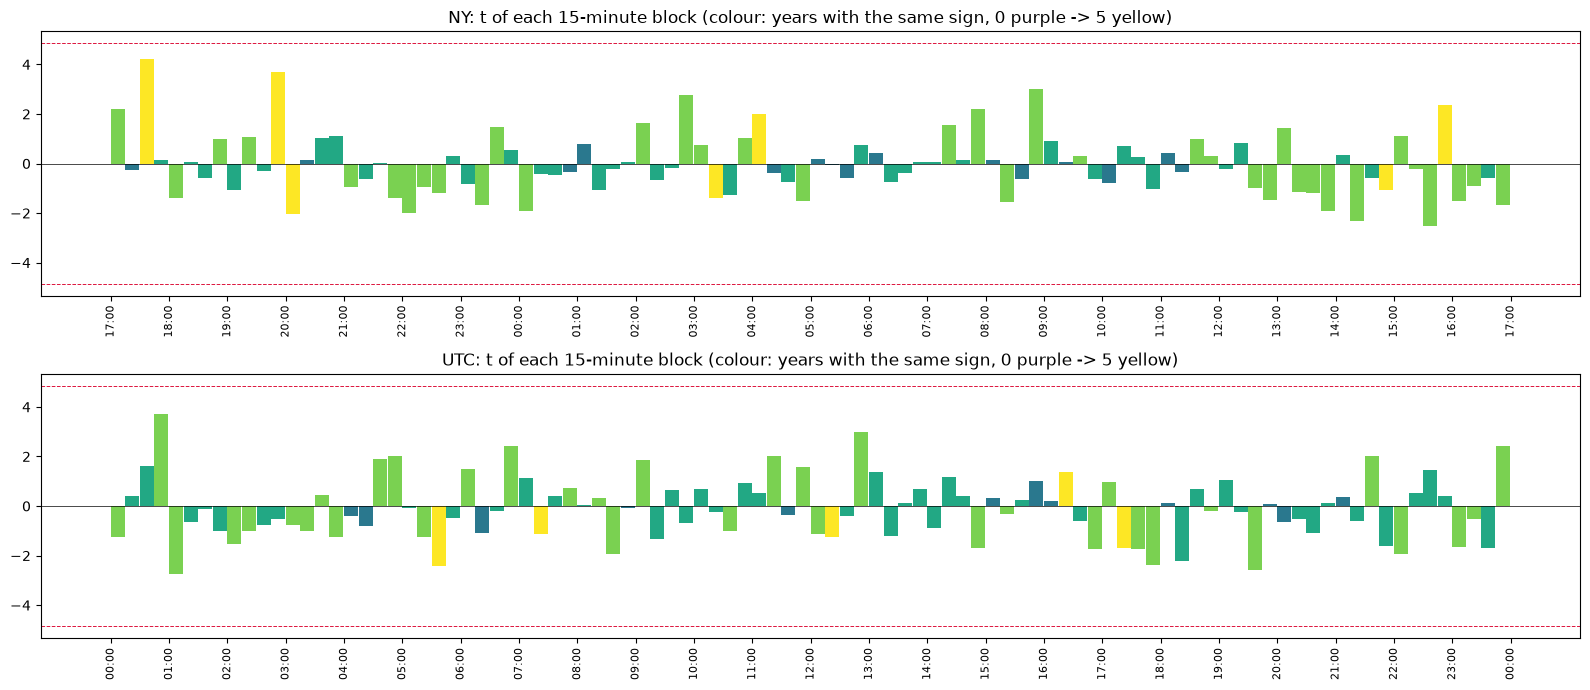

,clock,start,time,mean_bps,t,share_up,years_same_sign,n_years
2,NY,30,NY 17:30,0.299,4.223,0.552,5,5
3,UTC,45,UTC 00:45,0.369,3.730,0.550,4,5
11,NY,165,NY 19:45,0.343,3.699,0.547,5,5
51,UTC,765,UTC 12:45,0.553,2.996,0.520,4,5
63,NY,945,NY 08:45,0.601,2.992,0.522,4,5
39,NY,585,NY 02:45,0.323,2.785,0.527,4,5
4,UTC,60,UTC 01:00,-0.309,-2.742,0.457,4,5
78,UTC,1170,UTC 19:30,-0.321,-2.580,0.462,4,5
90,NY,1350,NY 15:30,-0.275,-2.535,0.478,4,5
27,UTC,405,UTC 06:45,0.250,2.438,0.516,4,5


In [8]:
bc = {c: F.block_consistency(panels[(PAIR, c)], 15) for c in F.CLOCKS}
fig, axes = plt.subplots(2, 1, figsize=(16, 7))
for ax, clock in zip(axes, F.CLOCKS):
    b = bc[clock]
    ax.bar(b["start"] / 60, b["t"], width=0.24, color=plt.cm.viridis(b["years_same_sign"] / 5), align="edge")
    for s in (1, -1):
        ax.axhline(s * POOLED_T, color="crimson", ls="--", lw=0.7)
    ax.axhline(0, color="black", lw=0.5)
    t, l = HOURS(clock, 1); ax.set_xticks(np.array(t) / 60); ax.set_xticklabels(l, rotation=90, fontsize=8)
    ax.set_title(f"{clock}: t of each 15-minute block (colour: years with the same sign, 0 purple -> 5 yellow)")
plt.tight_layout(); plt.savefig(OUT / "01_blocks.png", dpi=110); plt.show()
pd.concat(bc, names=["clock"]).to_csv(OUT / "01_blocks.csv")
display(pd.concat(bc, names=["clock"]).reset_index(level=0).sort_values("t", key=abs, ascending=False).head(15).round(3))

## 7. Interval scan: D1–D3 and the frozen candidates

Map: t-statistic of every interval by start time (x) and length (y). Black dots: intervals passing D1–D3.

USDCAD: tests 2,704 | D1 8 | D1+D2 8 | D1+D2+D3 0 | candidates 0 | pooled-Bonferroni |t| 1


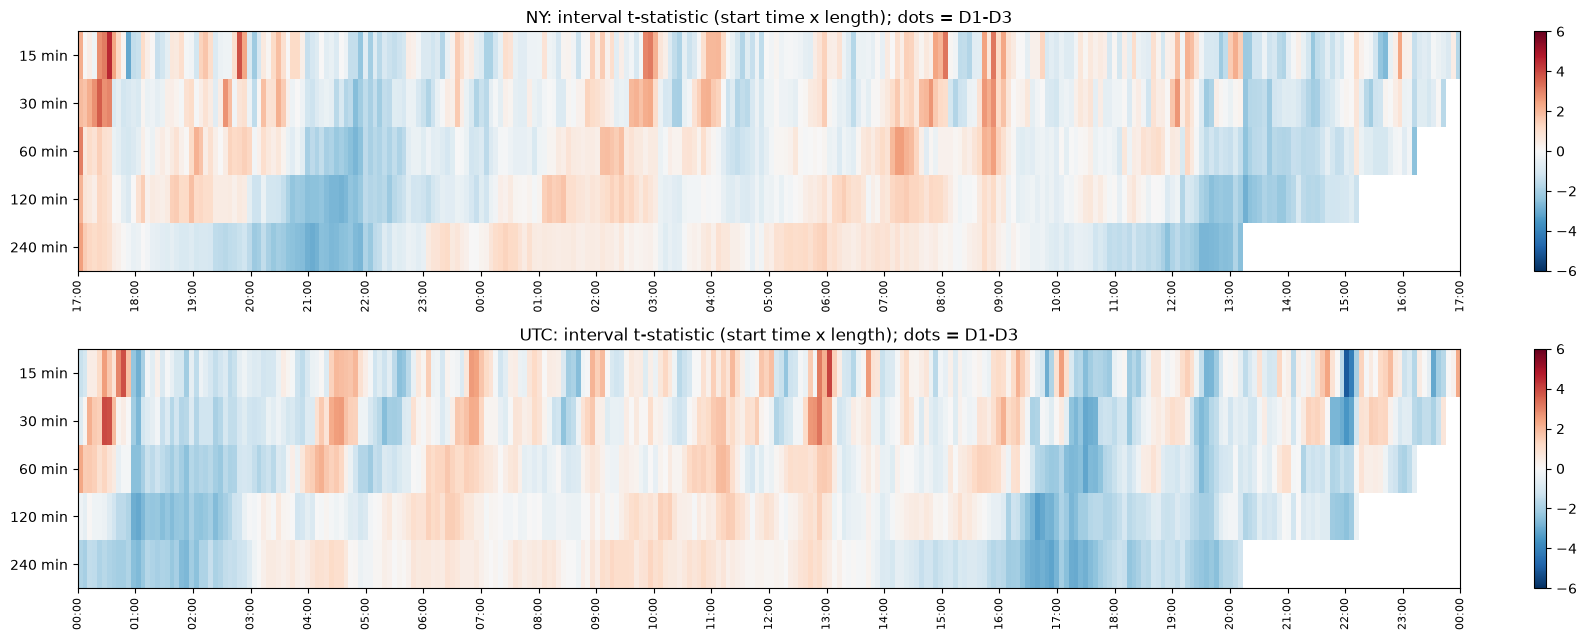

,id,pair,clock,start_time,end_time,minutes,direction,mean_bps,t,q,years_same_sign,cost_bps,pooled_bonferroni,n_days,start,end


frozen: candidates_frozen.csv sha256 fce53799248dc2ac04cec6aa077066c6e03310c83a2e7c2f654c84be980d15c7


In [9]:
scan = pd.concat([F.scan_panel(panels[(PAIR, c)], cfg) for c in F.CLOCKS], ignore_index=True)
scan, cand = F.select_candidates(scan, cfg)
scan["D123"] = scan["D1"] & scan["D2"] & scan["D3"]
scan["pooled_bonferroni"] = scan["t"].abs() >= POOLED_T
print(f"{PAIR}: tests {len(scan):,} | D1 {int(scan['D1'].sum())} | D1+D2 {int((scan['D1'] & scan['D2']).sum())} | "
      f"D1+D2+D3 {int(scan['D123'].sum())} | candidates {len(cand)} | pooled-Bonferroni |t| {int(scan['pooled_bonferroni'].sum())}")
fig, axes = plt.subplots(2, 1, figsize=(16, 6.5))
for ax, clock in zip(axes, F.CLOCKS):
    s = scan[scan["clock"] == clock]
    grid = s.pivot(index="minutes", columns="start", values="t")
    im = ax.imshow(grid.to_numpy(), aspect="auto", cmap="RdBu_r", vmin=-6, vmax=6,
                   extent=[0, 24, len(grid) - 0.5, -0.5], interpolation="nearest")
    hit = s[s["D123"]]
    ax.scatter(hit["start"] / 60, [list(grid.index).index(m) for m in hit["minutes"]], s=6, color="black")
    ax.set_yticks(range(len(grid))); ax.set_yticklabels([f"{m} min" for m in grid.index])
    t, l = HOURS(clock, 1); ax.set_xticks(np.array(t) / 60); ax.set_xticklabels(l, rotation=90, fontsize=8)
    ax.set_title(f"{clock}: interval t-statistic (start time x length); dots = D1-D3")
    fig.colorbar(im, ax=ax, fraction=0.015)
plt.tight_layout(); plt.savefig(OUT / "01_scan_map.png", dpi=110); plt.show()
cand["pooled_bonferroni"] = cand["t"].abs() >= POOLED_T
cols = ["id", "pair", "clock", "start_time", "end_time", "minutes", "direction", "mean_bps", "t", "q",
        "years_same_sign", "cost_bps", "pooled_bonferroni", "n_days", "start", "end"]
cand = cand[cols] if len(cand) else pd.DataFrame(columns=cols)
display(cand.round(3))
scan[scan["D1"]].to_csv(OUT / "01_scan_D1.csv", index=False)
frozen = OUT / "candidates_frozen.csv"
cand.to_csv(frozen, index=False, float_format="%.6f")
sha = F.file_sha256(frozen)
print("frozen:", frozen.name, "sha256", sha)

## 8. Where the candidates sit

In [10]:
if len(cand):
    n = len(cand)
    fig, axes = plt.subplots(int(np.ceil(n / 2)), 2, figsize=(16, 3.2 * np.ceil(n / 2)), squeeze=False)
    for ax, (_, r) in zip(axes.flat, cand.iterrows()):
        pr = prof[r["clock"]]
        ax.plot(pr.index / 60, pr["cum_mean_bps"], lw=1)
        ax.axvspan(r["start"] / 60, r["end"] / 60, color="green" if r["direction"] > 0 else "red", alpha=0.2)
        ax.axhline(0, color="black", lw=0.5)
        ax.set_title(f"{r['id']} {r['start_time']}-{r['end_time'].split()[1]} {'long' if r['direction'] > 0 else 'short'}: "
                     f"{r['mean_bps']:.2f} bp/day, t={r['t']:.1f}, cost {r['cost_bps']:.2f} bp", fontsize=9)
        t, l = HOURS(r["clock"], 2); ax.set_xticks(np.array(t) / 60); ax.set_xticklabels(l, fontsize=8)
    for ax in axes.flat[n:]:
        ax.axis("off")
    plt.tight_layout(); plt.savefig(OUT / "01_candidates.png", dpi=110); plt.show()
else:
    print("no candidates")

no candidates


## 9. D0: rotated-day placebos

Each day's 1-minute returns rotated by a random offset (same returns and daily move, time of day destroyed); the full pipeline rerun 20 times.

In [11]:
pl = F.placebo_counts(panels, cfg)
real = int(scan["D123"].sum())
p95 = float(np.percentile(pl["D1_D2_D3"], 95))
d0 = "STRUCTURE_FOUND" if real > p95 else "NO_STRUCTURE"
display(pl.describe().loc[["mean", "50%", "max"]])
print(f"{PAIR}: real D1-D3 {real} vs placebo 95th percentile {p95:.1f} -> {d0}")
pl.to_csv(OUT / "01_placebo.csv", index=False)

,run,D1,D1_D2_D3,candidates
mean,9.5,0.0,0.0,0.0
50%,9.5,0.0,0.0,0.0
max,19.0,0.0,0.0,0.0


USDCAD: real D1-D3 0 vs placebo 95th percentile 0.0 -> NO_STRUCTURE


In [12]:
summary = {"study": "FXS01", "pair": PAIR, "fxs_version": F.FXS_VERSION, "synthetic": SYNTHETIC,
           "window": [str(START), str(END)], "files": {k: cov[k] for k in ("expected", "present", "share")},
           "tests": int(len(scan)), "D1": int(scan["D1"].sum()), "D1_D2": int((scan["D1"] & scan["D2"]).sum()),
           "D1_D2_D3": real, "candidates": int(len(cand)), "pooled_bonferroni_candidates": int(cand["pooled_bonferroni"].sum()) if len(cand) else 0,
           "placebo_D1_D2_D3": pl["D1_D2_D3"].tolist(), "D0": d0, "candidates_sha256": sha,
           "config": {k: (list(v) if isinstance(v, tuple) else v) for k, v in asdict(cfg).items()}}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=str))
print(json.dumps({k: summary[k] for k in ("pair", "D1", "D1_D2", "D1_D2_D3", "candidates", "pooled_bonferroni_candidates", "D0")}, indent=2))

{
  "pair": "USDCAD",
  "D1": 8,
  "D1_D2": 8,
  "D1_D2_D3": 0,
  "candidates": 0,
  "pooled_bonferroni_candidates": 0,
  "D0": "NO_STRUCTURE"
}
